<a href="https://colab.research.google.com/github/VTKhanhLinh/TH_MachineLearning/blob/main/Tuan1/Bai_Tap_O_Lop/Bai1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Bài 1: Gỉa sử có một tập dữ liệu giả định và có các cột Diện tích nhà (m2) và giá bán(vnd)
1. Xây dựng mô hình hồi quy tuyến tính đơn giản dự đoán giá bán dựa trên diện tích.
2. Thêm số lượng dữ liệu và độ nhiễu để xem mô hình hoạt động như thế nào.
3. Thêm các biến đầu vào khác để nâng cao tính phức tạp của mô hình.


1. Xây dựng mô hình hồi quy tuyến tính đơn giản dự đoán giá bán dựa trên diện tích.

In [9]:
#Khai báo thư viện
import numpy as np #Thư viện hỗ trợ tính toán số học, mảng và ma trận.
import pandas as pd #Thư viện dùng để xử lý và phân tích dữ liệu dạng bảng.
import matplotlib.pyplot as plt #Thư viện vẽ biểu đồ.

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

np.random.seed(42)

In [10]:
#Tạo dữ liệu giả định
dien_tich = np.linspace(30, 150, 20)
gia_ban = 300 + 20 * dien_tich + np.random.normal(0, 150, 20)

df = pd.DataFrame({
    "Diện tích": dien_tich,
    "Gía bán": gia_ban
})

print(df)

     Diện tích      Gía bán
0    30.000000   974.507123
1    36.315789  1005.576144
2    42.631579  1249.784860
3    48.947368  1507.401847
4    55.263158  1370.140152
5    61.578947  1496.458404
6    67.894737  1894.776659
7    74.210526  1899.325736
8    80.526316  1840.105158
9    86.842105  2118.226112
10   93.157895  2093.645241
11   99.473684  2219.614221
12  105.789474  2452.083814
13  112.105263  2255.113226
14  118.421053  2409.683378
15  124.736842  2710.393713
16  131.052632  2769.127964
17  137.368421  3094.505521
18  143.684211  3037.480599
19  150.000000  3088.154445


In [12]:
X = df[["Diện tích"]]
y = df["Gía bán"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Hệ số góc:", model.coef_[0])
print("Hệ số chặn:", model.intercept_)
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R²:", r2_score(y_test, y_pred))

Hệ số góc: 16.514259007667995
Hệ số chặn: 587.4428704806407
MAE: 147.87447175382474
RMSE: 162.46875793112218
R²: 0.971705010963681


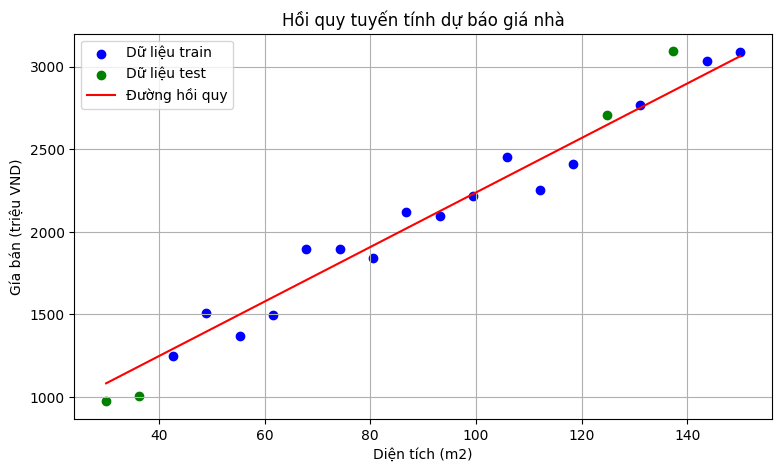

In [13]:
X_line = pd.DataFrame({
    "Diện tích": np.linspace(30, 150, 100)
})

y_line = model.predict(X_line)

plt.figure(figsize=(9, 5))

plt.scatter(X_train["Diện tích"], y_train,
            color="blue", label="Dữ liệu train")

plt.scatter(X_test["Diện tích"], y_test,
            color="green", label="Dữ liệu test")

plt.plot(X_line["Diện tích"], y_line,
         color="red", label="Đường hồi quy")

plt.xlabel("Diện tích (m2)")
plt.ylabel("Gía bán (triệu VND)")
plt.title("Hồi quy tuyến tính dự báo giá nhà")
plt.legend()
plt.grid(True)
plt.show()

2. Thêm số lượng dữ liệu và độ nhiễu để xem mô hình hoạt động như thế nào.

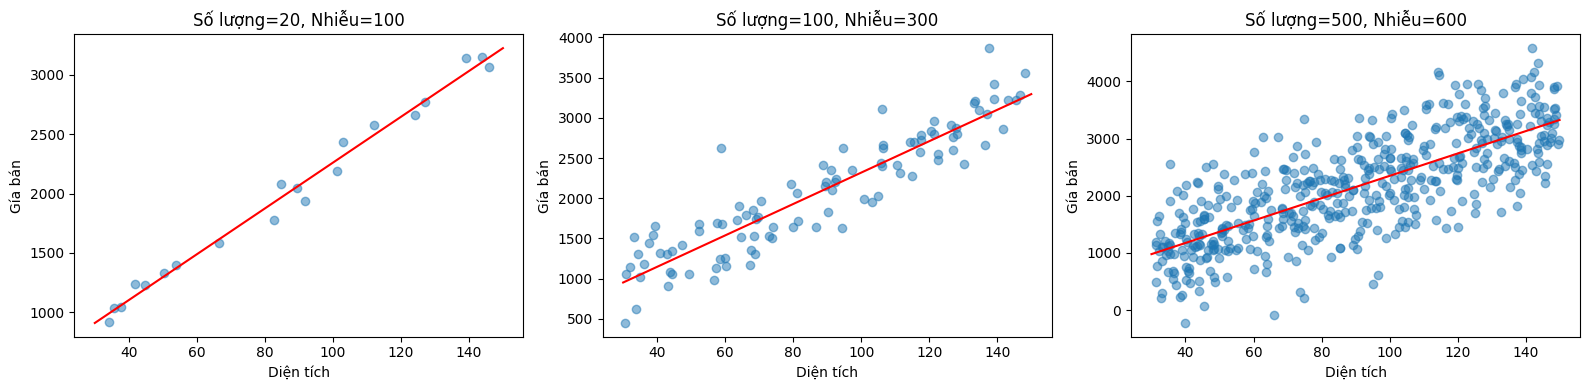

In [14]:
so_luong = [20, 100, 500]
do_nhieu = [100, 300, 600]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for i in range(3):
    n = so_luong[i]
    noise = do_nhieu[i]

    x = np.random.uniform(30, 150, n)
    y = 300 + 20 * x + np.random.normal(0, noise, n)

    X = x.reshape(-1, 1)

    model_temp = LinearRegression()
    model_temp.fit(X, y)

    x_line = np.linspace(30, 150, 100).reshape(-1, 1)
    y_line = model_temp.predict(x_line)

    axes[i].scatter(x, y, alpha=0.5)
    axes[i].plot(x_line, y_line, color="red")
    axes[i].set_title(f"Số lượng={n}, Nhiễu={noise}")
    axes[i].set_xlabel("Diện tích")
    axes[i].set_ylabel("Gía bán")

plt.tight_layout()
plt.show()

3. Thêm các biến đầu vào khác để nâng cao tính phức tạp của mô hình.


In [15]:
n = 200

dien_tich = np.random.uniform(30, 200, n)
so_phong = np.random.randint(1, 6, n)
tuoi_nha = np.random.randint(0, 31, n)

gia_ban = (
    300
    + 20 * dien_tich
    + 150 * so_phong
    - 15 * tuoi_nha
    + np.random.normal(0, 200, n)
)

df_multi = pd.DataFrame({
    "Diện tích": dien_tich,
    "Số phòng": so_phong,
    "Tuổi nhà": tuoi_nha,
    "Gía bán": gia_ban
})

print(df_multi.head())

    Diện tích  Số phòng  Tuổi nhà      Gía bán
0  177.713847         2        10  3790.026117
1  127.003657         5        19  3306.243606
2   35.165800         2        14  1406.063126
3  188.261278         1        18  3695.176265
4  147.219548         5         6  3768.895822


In [16]:
X = df_multi[["Diện tích", "Số phòng", "Tuổi nhà"]]
y = df_multi["Gía bán"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model_multi = LinearRegression()
model_multi.fit(X_train, y_train)

y_pred = model_multi.predict(X_test)

print("Hệ số:", model_multi.coef_)
print("Hệ số chặn:", model_multi.intercept_)
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2:", r2_score(y_test, y_pred))

Hệ số: [ 19.91038062 161.24358848 -11.64597507]
Hệ số chặn: 215.76722025915524
MAE: 166.3976575885426
RMSE: 207.83844681266038
R2: 0.9576421898548463


In [17]:
nha_moi = pd.DataFrame({
    "Diện tích": [100],
    "Số phòng": [3],
    "Tuổi nhà": [5]
})

gia_du_doan = model_multi.predict(nha_moi)

print(f"Gía nhà dự báo: {gia_du_doan[0]:,.2f} triệu VND")

Gía nhà dự báo: 2,632.31 triệu VND
